In [ ]:
import os, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img

root = "D:\\campus\\PlantVillage"  
assert os.path.exists(root), f"{root} not found. Update the path."

rows = []
for cls in sorted(os.listdir(root)):
    cls_dir = os.path.join(root, cls)
    if not os.path.isdir(cls_dir): 
        continue
    for img in glob.glob(os.path.join(cls_dir, "*.jpg")) + glob.glob(os.path.join(cls_dir, "*.png")):
        rows.append({"filepath": img, "label": cls})
df = pd.DataFrame(rows)
print("Total images found:", len(df))
df.head()

Total images found: 8170


,filepath,label
0,C:\Users\User\Desktop\AIML Dataset\PlantVillag...,Pepper__bell___Bacterial_spot
1,C:\Users\User\Desktop\AIML Dataset\PlantVillag...,Pepper__bell___Bacterial_spot
2,C:\Users\User\Desktop\AIML Dataset\PlantVillag...,Pepper__bell___Bacterial_spot
3,C:\Users\User\Desktop\AIML Dataset\PlantVillag...,Pepper__bell___Bacterial_spot
4,C:\Users\User\Desktop\AIML Dataset\PlantVillag...,Pepper__bell___Bacterial_spot


In [ ]:
datagen = ImageDataGenerator(
    rotation_range=20,    
    width_shift_range=0.2,  
    height_shift_range=0.2,  
    shear_range=0.2,         
    zoom_range=0.2,        
    horizontal_flip=True,    
    fill_mode='nearest'      
)

sample_img_path = df.sample(1, random_state=42)['filepath'].values[0]
img = load_img(sample_img_path, target_size=(128,128))  
x = img_to_array(img)  
x = np.expand_dims(x, axis=0)  

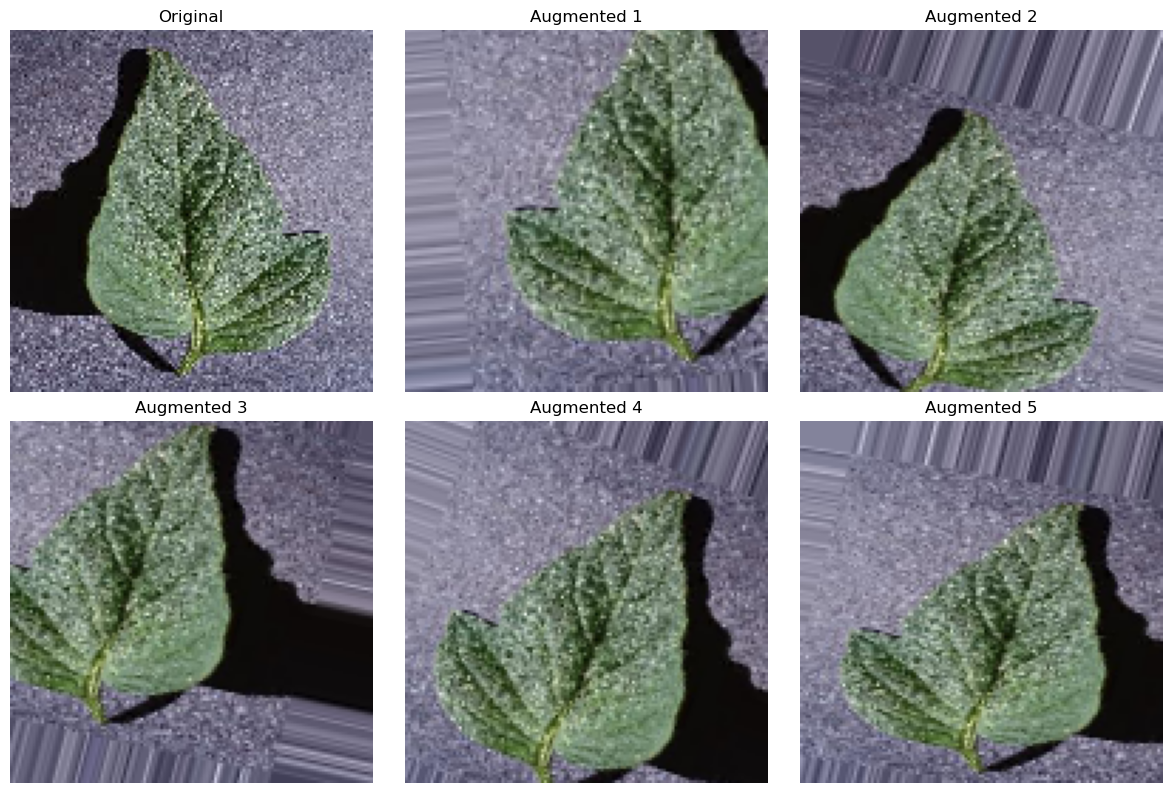

In [ ]:

plt.figure(figsize=(12,8))

plt.subplot(2, 3, 1)
plt.imshow(img)
plt.title("Original")
plt.axis("off")

i = 2
for batch in datagen.flow(x, batch_size=1, seed=42):
    plt.subplot(2, 3, i)
    plt.imshow(batch[0].astype("uint8"))
    plt.title(f"Augmented {i-1}")
    plt.axis("off")
    i += 1
    if i > 6:  
        break

plt.tight_layout()
plt.show()

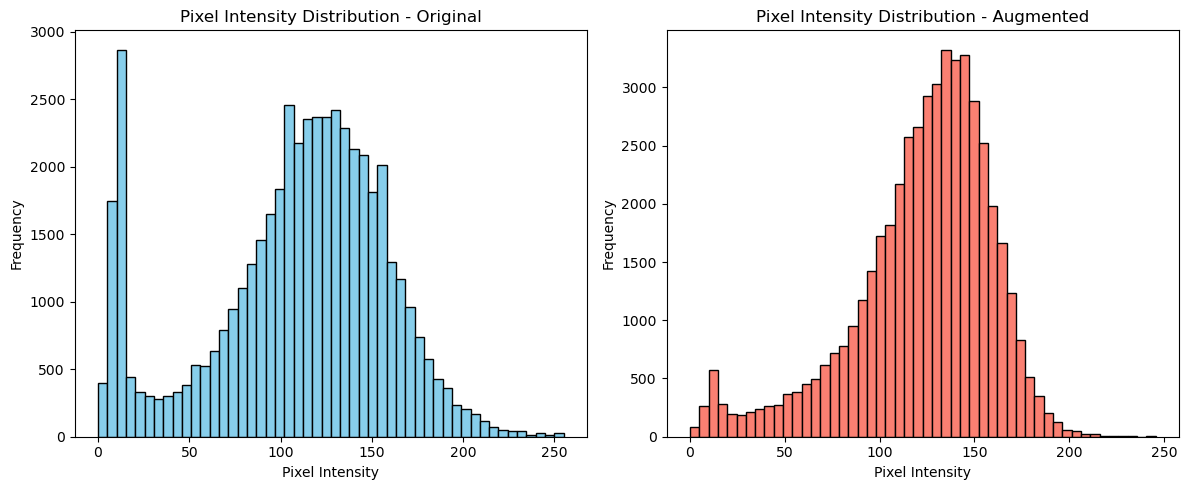

In [ ]:



original_array = img_to_array(img).astype("float32").flatten()


augmented_array = next(datagen.flow(x, batch_size=1, seed=42))[0].astype("float32").flatten()

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.hist(original_array, bins=50, color='skyblue', edgecolor='black')
plt.title("Pixel Intensity Distribution - Original")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.subplot(1,2,2)
plt.hist(augmented_array, bins=50, color='salmon', edgecolor='black')
plt.title("Pixel Intensity Distribution - Augmented")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()
